# ЛР2. Вывод модели в эксплуатацию — вариант 1 (отток клиентов Telco)

Терехин А., группа 23ИВ1б. Дисциплина «Прикладные задачи искусственного интеллекта», ПензГТУ.

Модель ЛР1 (LightGBM, порог 0,10, ROC-AUC на тесте 0,849) превращается в воспроизводимый сервис:
модули `src/`, журнал экспериментов и реестр MLflow, REST-сервис FastAPI, тесты pytest,
нагрузочный тест Locust, отчёт Evidently о дрейфе, интерфейс Gradio.
Доп. задание: журнал запросов сервиса и суточный отчёт о распределении прогнозов.

**Требования варианта 1:** режим пакетный, раз в сутки; пакет 10 000 клиентов за 60 с;
сценарий дрейфа — рост доли помесячных договоров.

Ноутбук выполняется сверху вниз после сброса среды выполнения
(«Среда выполнения → Перезапустить среду выполнения и выполнить всё»). Среда — без ускорителя.
Единственное ручное действие — подтверждение доступа к Google Диску.

## Шаг 1. Подготовка проекта

In [1]:
import os, sys, pathlib, time
T_START = time.time()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# каталог проекта на Диске: модель, данные и журнал экспериментов переживают сброс среды
PROJECT = os.environ.get('LAB2_PROJECT', '/content/drive/MyDrive/lab2_terekhin')
for sub in ['src', 'tests', 'data', 'models', 'mlruns', 'reports', 'logs']:
    pathlib.Path(f'{PROJECT}/{sub}').mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
if PROJECT not in sys.path:
    sys.path.insert(0, PROJECT)
print(os.getcwd(), '| Colab' if IN_COLAB else '| вне Colab', '| Python', sys.version.split()[0])

/content/drive/MyDrive/lab2_terekhin | вне Colab | Python 3.13.17


Версии библиотек зафиксированы. Методичка ориентирует на ветки `mlflow 2`, `evidently 0.4`, `gradio 4`,
`scikit-learn 1.5`; на Python 3.12+ и pandas 3 они не устанавливаются, поэтому взяты актуальные
совместимые версии (scikit-learn и LightGBM — те же, что в ЛР1). Код Evidently написан под API ветки 0.7.

In [2]:
%pip install -q "scikit-learn==1.9.1" "lightgbm==4.7.0" "fastapi==0.161.1" "uvicorn==0.54.0" \
    "pydantic==2.14.1" "mlflow==3.17.2" "evidently==0.7.23" "locust==2.47.0" "gradio==6.30.0" \
    "nest-asyncio==1.6.0" "pytest==9.1.1" "httpx==0.28.1" "requests==2.34.2"

Note: you may need to restart the kernel to use updated packages.


In [3]:
import importlib.metadata as md
PINNED = {'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'fastapi': '0.161.1', 'uvicorn': '0.54.0',
          'pydantic': '2.14.1', 'mlflow': '3.17.2', 'evidently': '0.7.23', 'locust': '2.47.0',
          'gradio': '6.30.0', 'pytest': '9.1.1', 'httpx': '0.28.1'}
# если pip обновил уже импортированный numpy/pandas, Colab требует перезапуск: делаем его сами
for mod in ['numpy', 'pandas']:
    if mod in sys.modules and sys.modules[mod].__version__ != md.version(mod):
        print(f'{mod} обновлён установкой — перезапуск среды; затем снова «Выполнить всё»')
        os.kill(os.getpid(), 9)
for pkg, ver in PINNED.items():
    assert md.version(pkg) == ver, (pkg, md.version(pkg), ver)
print({p: md.version(p) for p in ['numpy', 'pandas', *PINNED]})

{'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'fastapi': '0.161.1', 'uvicorn': '0.54.0', 'pydantic': '2.14.1', 'mlflow': '3.17.2', 'evidently': '0.7.23', 'locust': '2.47.0', 'gradio': '6.30.0', 'pytest': '9.1.1', 'httpx': '0.28.1'}


In [4]:
import json, random, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42                 # разбиение, модели, сценарии дрейфа
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
os.environ['PYTHONHASHSEED'] = str(RANDOM_STATE)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

## Шаг 2. Код в модулях

Модули записываются из ноутбука командой `%%writefile`. `features.py` перенесён из ЛР1 без изменения логики
(убраны только обёртки CatBoost, которые в финальную модель не вошли). Модули при импорте ничего не выполняют.

In [5]:
%%writefile src/__init__.py
"""Пакет ЛР2: признаки, обучение, предсказание, мониторинг, сервис."""

Overwriting src/__init__.py


In [6]:
%%writefile src/features.py
"""Признаки варианта 1 (отток клиентов Telco). Импортируется и ноутбуком, и сервисом.

Перенесено из features.py ЛР1. Модуль ничего не выполняет при импорте:
только константы, функции и классы. Сохранённый пайплайн ссылается на
src.features.add_features, поэтому загружается в любом процессе, где
доступен пакет src.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

RANDOM_STATE = 42

# входные столбцы модели (без customerID и целевой переменной)
INPUT_COLUMNS = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
                 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
                 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
                 'MonthlyCharges', 'TotalCharges']

SERVICES = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
PROTECTION = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
INTERNET_OPTIONS = PROTECTION + ['StreamingTV', 'StreamingMovies']

# все новые признаки ЛР1; по итогам абляции в финальной модели оставлен только n_services
NEW_FEATURES = ['avg_monthly_charge', 'charge_increase', 'n_services',
                'contract_payment', 'fiber_no_protection', 'auto_payment',
                'tenure_bucket']
KEPT_FEATURES = ['n_services']
DROP_FEATURES = [f for f in NEW_FEATURES if f not in KEPT_FEATURES]


def clean(X: pd.DataFrame) -> pd.DataFrame:
    """Очистка сырых данных: приведение типов, удаление идентификатора."""
    X = X.copy()
    X = X.drop(columns=['customerID', 'Churn'], errors='ignore')
    # у новых клиентов (tenure = 0) TotalCharges — пустая строка или пропуск
    X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')
    X.loc[X['TotalCharges'].isna() & (X['tenure'] == 0), 'TotalCharges'] = 0.0
    X['SeniorCitizen'] = X['SeniorCitizen'].map({0: 'No', 1: 'Yes'}).fillna(
        X['SeniorCitizen'].astype(str))
    return X


def add_features(X: pd.DataFrame, drop=()) -> pd.DataFrame:
    """Новые признаки ЛР1; drop — имена признаков, которые не создавать."""
    X = clean(X)
    tenure_safe = X['tenure'].replace(0, np.nan)
    # средний фактический платёж за месяц за всё время обслуживания
    X['avg_monthly_charge'] = (X['TotalCharges'] / tenure_safe).fillna(X['MonthlyCharges'])
    # насколько текущий тариф выше исторического среднего (рост цены)
    X['charge_increase'] = X['MonthlyCharges'] - X['avg_monthly_charge']
    # число подключённых услуг
    X['n_services'] = (X[SERVICES] == 'Yes').sum(axis=1) + (X['InternetService'] != 'No')
    # сочетание типа договора и способа оплаты
    X['contract_payment'] = X['Contract'] + ' | ' + X['PaymentMethod']
    # оптоволокно без единой услуги защиты/поддержки
    X['fiber_no_protection'] = ((X['InternetService'] == 'Fiber optic')
                                & (X[PROTECTION] != 'Yes').all(axis=1)).astype(int)
    # автоматический платёж
    X['auto_payment'] = X['PaymentMethod'].str.contains('automatic').astype(int)
    # стаж в годах (0–6)
    X['tenure_bucket'] = np.minimum(X['tenure'] // 12, 6).astype(int)
    return X.drop(columns=list(drop))


def to_category(X: pd.DataFrame) -> pd.DataFrame:
    """Строковые столбцы — в тип category."""
    X = X.copy()
    cols = X.select_dtypes(exclude='number').columns
    X[cols] = X[cols].astype(str).astype('category')
    return X


def cat_columns(X: pd.DataFrame) -> list:
    return X.select_dtypes(exclude='number').columns.tolist()


class CategoryAligner(TransformerMixin, BaseEstimator):
    """Переводит строковые столбцы в category с категориями, запомненными на fit.

    Одинаковое кодирование категорий на обучении и на новых данных;
    неизвестные значения становятся NaN (LightGBM обрабатывает пропуски сам).
    """

    def fit(self, X, y=None):
        self.categories_ = {c: sorted(X[c].dropna().astype(str).unique())
                            for c in cat_columns(X)}
        return self

    def transform(self, X):
        X = X.copy()
        for c, cats in self.categories_.items():
            X[c] = pd.Categorical(X[c].astype(str), categories=cats)
        return X


Overwriting src/features.py


In [7]:
%%writefile src/train.py
"""Загрузка данных, разбиение, обучение и оценка моделей (ЛР2, вариант 1).

Функции принимают данные и параметры и возвращают результат; трекинг в
MLflow выполняется в ноутбуке. При импорте ничего не выполняется.
"""
import hashlib

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.features import (DROP_FEATURES, INPUT_COLUMNS, RANDOM_STATE, CategoryAligner,
                          add_features, clean)

C_FN, C_FP = 6000.0, 800.0      # пропуск уходящего клиента / скидка лояльному, ₽ (из ЛР1)
THRESHOLD = 0.10                # порог ЛР1, выбран по минимуму стоимости ошибок на OOF

LGB_BASE = dict(random_state=RANDOM_STATE, verbose=-1, n_jobs=4)
# лучшие параметры LightGBM из Optuna в ЛР1 (60 испытаний, 5-кратная CV)
LGB_TUNED = dict(n_estimators=350, learning_rate=0.012719593273367318, num_leaves=7,
                 min_child_samples=49, subsample=0.642798783336023,
                 colsample_bytree=0.7057136719967809, reg_lambda=0.00231741384605258,
                 cat_smooth=2.988684085052872, subsample_freq=1, **LGB_BASE)


def file_md5(path: str) -> str:
    """Версия данных — MD5 файла."""
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()


def load_data(path: str):
    """Сырые данные Telco -> (X, y); X содержит customerID и 19 входных признаков."""
    raw = pd.read_csv(path)
    y = (raw['Churn'] == 'Yes').astype(int)
    X = raw[['customerID'] + INPUT_COLUMNS]
    return X, y


def split(X, y, test_size=0.2):
    """То же разбиение, что в ЛР1: стратифицированное, random_state = 42."""
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=RANDOM_STATE)


def make_model(kind: str, params: dict | None = None, drop=DROP_FEATURES):
    """Пайплайн «сырые столбцы -> вероятность»; признаки строятся внутри пайплайна."""
    params = params or {}
    if kind == 'lightgbm':
        return make_pipeline(FunctionTransformer(add_features, kw_args={'drop': list(drop)}),
                             CategoryAligner(), lgb.LGBMClassifier(**{**LGB_BASE, **params}))
    if kind == 'logreg':
        preprocess = ColumnTransformer([
            ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
             make_column_selector(dtype_include='number')),
            ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                min_frequency=0.01)),
             make_column_selector(dtype_exclude='number')),
        ])
        return make_pipeline(FunctionTransformer(clean), preprocess,
                             LogisticRegression(max_iter=2000, **params))
    raise ValueError(f'неизвестный тип модели: {kind}')


def train_model(X_train, y_train, params: dict | None = None, kind: str = 'lightgbm',
                drop=DROP_FEATURES):
    """Обучает пайплайн на сырых данных и возвращает его."""
    return make_model(kind, params, drop).fit(X_train, y_train)


def cv_roc_auc(X_train, y_train, params=None, kind='lightgbm', drop=DROP_FEATURES, n_splits=5):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    return cross_val_score(make_model(kind, params, drop), X_train, y_train, cv=cv,
                           scoring='roc_auc')


def total_cost(y_true, proba, threshold, c_fn=C_FN, c_fp=C_FP) -> float:
    """Стоимость ошибок, ₽: пропущенные уходящие и скидки лояльным."""
    y_true, pred = np.asarray(y_true), np.asarray(proba) >= threshold
    return float(c_fn * ((y_true == 1) & ~pred).sum() + c_fp * ((y_true == 0) & pred).sum())


def evaluate(y_true, proba, threshold=THRESHOLD) -> dict:
    return {'roc_auc_test': float(roc_auc_score(y_true, proba)),
            'pr_auc_test': float(average_precision_score(y_true, proba)),
            'brier_test': float(brier_score_loss(y_true, proba)),
            'cost_per_client_test': total_cost(y_true, proba, threshold) / len(y_true)}


def make_input_schema(X_train, threshold=THRESHOLD) -> dict:
    """Описание входа (как input_schema.json ЛР1): тип, диапазон или допустимые значения."""
    X = X_train[INPUT_COLUMNS]
    features = {}
    for col in INPUT_COLUMNS:
        s = X[col]
        if pd.api.types.is_numeric_dtype(s):
            features[col] = {'type': 'integer' if pd.api.types.is_integer_dtype(s) else 'number',
                             'min': float(s.min()), 'max': float(s.max())}
        else:
            features[col] = {'type': 'category',
                             'values': sorted(s.dropna().astype(str).unique().tolist())}
    features['TotalCharges'] = {'type': 'number', 'nullable': True, 'min': 0.0,
                                'max': float(clean(X_train)['TotalCharges'].max())}
    return {'description': 'Вход модели оттока Telco. Одна строка — один клиент на дату среза.',
            'target': {'name': 'Churn', 'positive': 'Yes'},
            'threshold': threshold, 'optional_columns': ['customerID'], 'features': features}


Overwriting src/train.py


In [8]:
%%writefile src/predict.py
"""Загрузка модели из реестра MLflow и предсказание по списку словарей.

При импорте ничего не выполняется; mlflow импортируется только при загрузке.
"""
import os

import numpy as np
import pandas as pd

from src.features import INPUT_COLUMNS

MODEL_NAME = 'lab2_terekhin'
MODEL_ALIAS = 'champion'


def tracking_uri() -> str:
    """Хранилище MLflow: переменная окружения или каталог mlruns в текущем каталоге проекта."""
    os.environ.setdefault('MLFLOW_ALLOW_FILE_STORE', 'true')   # файловый режим (MLflow 3)
    return os.environ.get('MLFLOW_TRACKING_URI') or f"file:{os.path.abspath('mlruns')}"


def load_registered(name: str = MODEL_NAME, alias: str = MODEL_ALIAS) -> dict:
    """Загружает версию модели по имени и псевдониму реестра; порог берётся из тегов версии."""
    import mlflow
    import mlflow.sklearn
    from mlflow import MlflowClient

    mlflow.set_tracking_uri(tracking_uri())
    client = MlflowClient()
    mv = client.get_model_version_by_alias(name, alias)
    run = client.get_run(mv.run_id)
    pipeline = mlflow.sklearn.load_model(f'models:/{name}/{mv.version}')
    return {'pipeline': pipeline,
            'threshold': float(mv.tags['threshold']),
            'name': name, 'version': int(mv.version), 'alias': alias, 'run_id': mv.run_id,
            'model_type': run.data.tags.get('model_type', type(pipeline[-1]).__name__),
            'roc_auc_test': run.data.metrics.get('roc_auc_test'),
            'data_version': run.data.tags.get('data_version'),
            'features': list(INPUT_COLUMNS)}


def records_to_frame(records: list[dict]) -> pd.DataFrame:
    """Список словарей -> DataFrame с входными столбцами в порядке обучения."""
    return pd.DataFrame.from_records(records, columns=INPUT_COLUMNS)


def predict_proba(pipeline, records: list[dict]) -> np.ndarray:
    """Вероятности ухода для списка клиентов."""
    return pipeline.predict_proba(records_to_frame(records))[:, 1]


def frame_to_records(X: pd.DataFrame) -> list[dict]:
    """Сырые строки набора -> JSON-совместимые объекты запроса (пустой TotalCharges -> None)."""
    X = X[[c for c in ['customerID'] + INPUT_COLUMNS if c in X.columns]].copy()
    total = pd.to_numeric(X['TotalCharges'], errors='coerce').astype(object)
    X['TotalCharges'] = total.where(total.notna(), None)
    records = X.to_dict(orient='records')
    for r in records:
        r['SeniorCitizen'] = int(r['SeniorCitizen'])
        r['tenure'] = int(r['tenure'])
        r['MonthlyCharges'] = float(r['MonthlyCharges'])
    return records


Overwriting src/predict.py


In [9]:
%%writefile src/monitoring.py
"""Журнал запросов сервиса и суточный отчёт о распределении прогнозов (доп. задание).

PredictionLogger пишет записи JSONL в фоновом потоке, чтобы запись на диск
не добавлялась к задержке ответа. daily_report строит по журналу отчёт за
сутки: объём запросов, отказы, задержки, распределение вероятностей и его
сдвиг относительно эталона (PSI).
"""
import base64
import io
import json
import os
import queue
import threading
import time

import numpy as np
import pandas as pd


class PredictionLogger:
    def __init__(self, path: str):
        self.path = path
        if path:
            os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
        self._q: queue.Queue = queue.Queue()
        self._thread = threading.Thread(target=self._writer, daemon=True)
        self._thread.start()

    def log(self, record: dict):
        if self.path:
            self._q.put({'ts': time.strftime('%Y-%m-%dT%H:%M:%S'), **record})

    def _writer(self):
        while True:
            rec = self._q.get()
            if rec is None:
                self._q.task_done()
                return
            with open(self.path, 'a', encoding='utf-8') as f:
                f.write(json.dumps(rec, ensure_ascii=False) + '\n')
            self._q.task_done()

    def flush(self):
        self._q.join()

    def close(self):
        self._q.put(None)
        self._thread.join(timeout=5)


def read_log(path: str) -> pd.DataFrame:
    with open(path, encoding='utf-8') as f:
        df = pd.DataFrame([json.loads(line) for line in f if line.strip()])
    df['ts'] = pd.to_datetime(df['ts'])
    df['day'] = df['ts'].dt.strftime('%Y-%m-%d')
    return df


def psi(reference, current, bins: int = 10) -> float:
    """Population Stability Index по квантильным корзинам эталона."""
    reference, current = np.asarray(reference), np.asarray(current)
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(reference, edges)[0] / len(reference)
    c = np.histogram(current, edges)[0] / len(current)
    r, c = np.clip(r, 1e-4, None), np.clip(c, 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))


def psi_level(value: float) -> str:
    if value < 0.1:
        return 'стабильно'
    return 'умеренный сдвиг' if value < 0.25 else 'значимый сдвиг'


def _hist_png(reference, current) -> str:
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6.5, 3))
    bins = np.linspace(0, 1, 26)
    ax.hist(reference, bins, density=True, alpha=0.5, label='эталон (тест ЛР1)')
    ax.hist(current, bins, density=True, alpha=0.5, label='прогнозы за сутки')
    ax.set_xlabel('вероятность ухода'); ax.set_ylabel('плотность'); ax.legend()
    fig.tight_layout()
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=110)
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()


def daily_report(log_path: str, day: str, reference_proba, threshold: float,
                 out_html: str | None = None) -> dict:
    """Суточный отчёт по журналу: возвращает сводку и (по желанию) сохраняет HTML."""
    log = read_log(log_path)
    log = log[log['day'] == day]
    ok = log[log['status'] == 200]
    proba = np.concatenate([np.asarray(p) for p in ok['proba']]) if len(ok) else np.array([])
    reference_proba = np.asarray(reference_proba)

    by_endpoint = log.groupby(['endpoint', 'status']).agg(
        requests=('ts', 'size'), objects=('n', 'sum'),
        latency_p50_ms=('latency_ms', 'median'),
        latency_p95_ms=('latency_ms', lambda s: s.quantile(0.95))).reset_index()

    batches = ok[ok['endpoint'] == '/predict-batch'].copy()
    batches['mean_proba'] = batches['proba'].map(np.mean)
    batches['share_offer'] = batches['proba'].map(lambda p: float(np.mean(np.asarray(p) >= threshold)))
    batches['psi'] = batches['proba'].map(lambda p: psi(reference_proba, p) if len(p) >= 100 else np.nan)
    batches['оценка'] = batches['psi'].map(lambda v: psi_level(v) if v == v else 'мало объектов')
    batches['n'] = batches['n'].astype(int)
    batches = batches[['ts', 'request_id', 'n', 'latency_ms', 'mean_proba', 'share_offer', 'psi', 'оценка']]

    summary = {
        'day': day, 'requests': int(len(log)), 'rejected_422': int((log['status'] == 422).sum()),
        'objects_scored': int(len(proba)),
        'mean_proba': float(proba.mean()) if len(proba) else None,
        'share_offer': float((proba >= threshold).mean()) if len(proba) else None,
        'expected_churners': float(proba.sum()),
        'ref_mean_proba': float(reference_proba.mean()),
        'ref_share_offer': float((reference_proba >= threshold).mean()),
        'psi_day': psi(reference_proba, proba) if len(proba) >= 100 else None,
    }
    summary['psi_level'] = psi_level(summary['psi_day']) if summary['psi_day'] is not None else '—'

    if out_html:
        q = np.quantile(proba, [0.1, 0.25, 0.5, 0.75, 0.9]) if len(proba) else [np.nan] * 5
        quant = pd.DataFrame({'квантиль': ['10%', '25%', '50%', '75%', '90%'],
                              'сутки': np.round(q, 4),
                              'эталон': np.round(np.quantile(reference_proba, [0.1, 0.25, 0.5, 0.75, 0.9]), 4)})
        img = _hist_png(reference_proba, proba) if len(proba) else ''
        html = f"""<html><head><meta charset="utf-8"><title>Суточный отчёт {day}</title>
<style>body{{font-family:sans-serif;margin:24px}}table{{border-collapse:collapse}}
td,th{{border:1px solid #bbb;padding:3px 8px;text-align:right}}</style></head><body>
<h2>Суточный отчёт о прогнозах сервиса оттока — {day}</h2>
<p>Запросов: {summary['requests']}, отклонено (422): {summary['rejected_422']},
оценено клиентов: {summary['objects_scored']}. Порог решения: {threshold}.</p>
<p>Средняя вероятность ухода: {summary['mean_proba']:.4f} (эталон {summary['ref_mean_proba']:.4f});
доля клиентов со скидкой: {summary['share_offer']:.3f} (эталон {summary['ref_share_offer']:.3f});
ожидаемое число уходящих: {summary['expected_churners']:.0f}.</p>
<p><b>PSI прогнозов за сутки: {summary['psi_day'] if summary['psi_day'] is None else round(summary['psi_day'], 4)}
— {summary['psi_level']}</b> (&lt;0,1 — стабильно, 0,1–0,25 — умеренный сдвиг, &gt;0,25 — значимый).</p>
<h3>Запросы по эндпоинтам</h3>{by_endpoint.round(2).to_html(index=False)}
<h3>Пакеты</h3>{batches.round(4).to_html(index=False)}
<h3>Квантили вероятности</h3>{quant.to_html(index=False)}
<img src="data:image/png;base64,{img}"></body></html>"""
        os.makedirs(os.path.dirname(out_html) or '.', exist_ok=True)
        with open(out_html, 'w', encoding='utf-8') as f:
            f.write(html)
    return {'summary': summary, 'by_endpoint': by_endpoint, 'batches': batches}


Overwriting src/monitoring.py


In [10]:
import importlib
import src.features as F, src.train as T, src.predict as PR, src.monitoring as MON
for m in (F, T, PR, MON):
    importlib.reload(m)

# модули импортируются в отдельном процессе и ничего не выполняют при импорте
out = subprocess.run([sys.executable, '-c', 'import src.features, src.train, src.predict, src.monitoring; print("ok")'],
                     capture_output=True, text=True, cwd=PROJECT)
print('импорт в отдельном процессе:', out.stdout.strip() or out.stderr[-500:])

импорт в отдельном процессе: ok


Данные варианта — тот же файл, что в ЛР1; версия данных фиксируется хешем MD5.

In [11]:
import urllib.request
DATA = 'data/telco.csv'
DATA_MD5 = '3b0bfab28a8101b4e4fdd08025a5c235'      # хеш файла из ЛР1
DATA_URL = ('https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/'
            'master/data/Telco-Customer-Churn.csv')   # зеркало набора Kaggle blastchar/telco-customer-churn
if not os.path.exists(DATA):
    urllib.request.urlretrieve(DATA_URL, DATA)
DATA_HASH = T.file_md5(DATA)
assert DATA_HASH == DATA_MD5, 'файл данных отличается от использованного в ЛР1'

X, y = T.load_data(DATA)
X_train, X_test, y_train, y_test = T.split(X, y)
print('данные', X.shape, '| md5', DATA_HASH)
print('train', X_train.shape, 'доля ушедших', round(y_train.mean(), 4), '| test', X_test.shape, round(y_test.mean(), 4))

данные (7043, 20) | md5 3b0bfab28a8101b4e4fdd08025a5c235
train (5634, 20) доля ушедших 0.2654 | test (1409, 20) 0.2654


In [12]:
# финальная модель ЛР1, обученная функцией из src/train.py: метрики должны совпасть с ЛР1 (ROC-AUC 0,8488)
lr1_model = T.train_model(X_train, y_train, T.LGB_TUNED)
lr1_metrics = T.evaluate(y_test, lr1_model.predict_proba(X_test)[:, 1])
print({k: round(v, 4) for k, v in lr1_metrics.items()})
assert abs(lr1_metrics['roc_auc_test'] - 0.8488) < 5e-4

{'roc_auc_test': 0.8488, 'pr_auc_test': 0.6646, 'brier_test': 0.1344, 'cost_per_client_test': 382.3989}


## Шаг 3. Трекинг в MLflow

Хранилище — каталог `mlruns/` на Диске (файловый режим; в MLflow 3 он включается переменной
`MLFLOW_ALLOW_FILE_STORE`). Для каждого запуска логируются параметры, метрики (CV на обучающей выборке и
тест), порог, описание входа, код признаков и сама модель с сигнатурой; тег `data_version` — MD5 данных.
Лучшая модель выбирается по ROC-AUC кросс-валидации (не по тесту), регистрируется в реестре под именем
`lab2_terekhin` и получает псевдоним `champion`; сервис загружает её по имени и псевдониму.

In [13]:
os.environ['MLFLOW_ALLOW_FILE_STORE'] = 'true'
os.environ['MLFLOW_TRACKING_URI'] = f'file:{PROJECT}/mlruns'
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
import logging
logging.getLogger('mlflow').setLevel(logging.ERROR)
import mlflow, mlflow.sklearn
from mlflow import MlflowClient
logging.getLogger('mlflow').setLevel(logging.ERROR)   # предупреждения о формате pickle — ожидаемые
from mlflow.models import infer_signature

mlflow.set_tracking_uri(os.environ['MLFLOW_TRACKING_URI'])
mlflow.set_experiment('lab2')
SESSION = time.strftime('%Y%m%d-%H%M%S')          # метка прогона ноутбука

schema = T.make_input_schema(X_train)
with open('models/input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

X_sig = F.clean(X_test)[F.INPUT_COLUMNS].head(50)  # для сигнатуры: типы после очистки


def log_run(run_name, kind, params, drop=F.DROP_FEATURES, note=''):
    with mlflow.start_run(run_name=run_name) as run:
        cv = T.cv_roc_auc(X_train, y_train, params, kind, drop)
        model = T.train_model(X_train, y_train, params, kind, drop)
        proba = model.predict_proba(X_test)[:, 1]
        mlflow.log_params({'kind': kind, 'dropped_features': ','.join(drop) if kind == 'lightgbm' else '-',
                           **params})
        mlflow.log_metrics({'cv_roc_auc_mean': float(cv.mean()), 'cv_roc_auc_std': float(cv.std()),
                            'threshold': T.THRESHOLD, **T.evaluate(y_test, proba)})
        mlflow.set_tags({'data_version': DATA_HASH, 'model_type': kind, 'session': SESSION,
                         'split': 'stratified 80/20, random_state=42', 'mlflow.note.content': note})
        mlflow.log_artifact('models/input_schema.json')
        # формат cloudpickle: пайплайн ссылается на функции src.features (skops их не допускает)
        info = mlflow.sklearn.log_model(model, name='model', code_paths=['src'],
                                        serialization_format='cloudpickle',
                                        signature=infer_signature(X_sig, proba[:50]),
                                        input_example=X_sig.head(3))
    print(f'{run_name:26s} CV {cv.mean():.4f} ± {cv.std():.4f} | тест {roc_auc_score(y_test, proba):.4f}')
    return run.info.run_id, info.model_uri


from sklearn.metrics import roc_auc_score
RUNS = {
    'logreg-baseline': log_run('logreg-baseline', 'logreg', {'C': 1.0},
                               note='логистическая регрессия на исходных признаках (baseline ЛР1)'),
    'lgbm-default': log_run('lgbm-default', 'lightgbm', {}, note='LightGBM с параметрами по умолчанию'),
    'lgbm-tuned-all-features': log_run('lgbm-tuned-all-features', 'lightgbm', T.LGB_TUNED, drop=[],
                                       note='параметры Optuna ЛР1, все 7 новых признаков'),
    'lgbm-tuned': log_run('lgbm-tuned', 'lightgbm', T.LGB_TUNED,
                          note='финальная модель ЛР1: параметры Optuna, из новых признаков только n_services'),
}

logreg-baseline            CV 0.8461 ± 0.0126 | тест 0.8420


lgbm-default               CV 0.8352 ± 0.0089 | тест 0.8357


lgbm-tuned-all-features    CV 0.8498 ± 0.0121 | тест 0.8480


lgbm-tuned                 CV 0.8511 ± 0.0119 | тест 0.8488


In [14]:
# сравнение запусков без веб-интерфейса
client = MlflowClient()
exp = client.get_experiment_by_name('lab2')
runs = mlflow.search_runs(experiment_ids=[exp.experiment_id], order_by=['metrics.cv_roc_auc_mean DESC'])
cols = ['tags.mlflow.runName', 'tags.session', 'metrics.cv_roc_auc_mean', 'metrics.cv_roc_auc_std',
        'metrics.roc_auc_test', 'metrics.pr_auc_test', 'metrics.cost_per_client_test',
        'params.num_leaves', 'tags.data_version']
runs_tab = runs[cols].rename(columns=lambda c: c.split('.', 1)[1])
runs_tab.to_csv('reports/mlflow_runs.csv', index=False)
runs_tab[runs_tab['session'] == SESSION].round(4)

,mlflow.runName,session,cv_roc_auc_mean,cv_roc_auc_std,roc_auc_test,pr_auc_test,cost_per_client_test,num_leaves,data_version
0,lgbm-tuned,20261023-173707,0.8511,0.0119,0.8488,0.6646,382.3989,7,3b0bfab28a8101b4e4fdd08025a5c235
2,lgbm-tuned-all-features,20261023-173707,0.8498,0.0121,0.8480,0.6653,380.9794,7,3b0bfab28a8101b4e4fdd08025a5c235
4,logreg-baseline,20261023-173707,0.8461,0.0126,0.8420,0.6337,379.2761,NaN,3b0bfab28a8101b4e4fdd08025a5c235
6,lgbm-default,20261023-173707,0.8352,0.0089,0.8357,0.6404,422.1434,NaN,3b0bfab28a8101b4e4fdd08025a5c235


In [15]:
# регистрация лучшей по CV модели текущего прогона
cur = runs[runs['tags.session'] == SESSION].sort_values('metrics.cv_roc_auc_mean', ascending=False)
best = cur.iloc[0]
best_name = best['tags.mlflow.runName']
MODEL_NAME = PR.MODEL_NAME
mv = mlflow.register_model(RUNS[best_name][1], MODEL_NAME)
for k, v in {'threshold': str(T.THRESHOLD), 'data_version': DATA_HASH, 'run_name': best_name,
             'roc_auc_test': f"{best['metrics.roc_auc_test']:.4f}"}.items():
    client.set_model_version_tag(MODEL_NAME, mv.version, k, v)
client.update_model_version(MODEL_NAME, mv.version,
                            description=f'{best_name}: лучшая ROC-AUC на 5-кратной CV; порог 0,10 из ЛР1')
client.set_registered_model_alias(MODEL_NAME, 'champion', mv.version)
print(f'зарегистрирована {MODEL_NAME} v{mv.version} ({best_name}), псевдоним champion')
pd.DataFrame([{'version': v.version, 'run': v.tags.get('run_name'), 'aliases': ','.join(v.aliases),
               'roc_auc_test': v.tags.get('roc_auc_test'), 'created': pd.to_datetime(v.creation_timestamp, unit='ms')}
              for v in client.search_model_versions(f"name='{MODEL_NAME}'")]).sort_values('version')

зарегистрирована lab2_terekhin v2 (lgbm-tuned), псевдоним champion


Registered model 'lab2_terekhin' already exists. Creating a new version of this model...
Created version '2' of model 'lab2_terekhin'.


,version,run,aliases,roc_auc_test,created
1,1,lgbm-tuned,,0.8488,2026-10-23 17:29:57.715
0,2,lgbm-tuned,champion,0.8488,2026-10-23 17:37:32.670


In [16]:
# загрузка по имени и версии из реестра: прогнозы совпадают с моделью в памяти и с моделью ЛР1
by_version = mlflow.sklearn.load_model(f'models:/{MODEL_NAME}/{mv.version}')
bundle = PR.load_registered()                       # по псевдониму champion — так загружает сервис
p_reg = bundle['pipeline'].predict_proba(X_test)[:, 1]
assert np.allclose(p_reg, by_version.predict_proba(X_test)[:, 1])
print('champion = версия', bundle['version'], '| порог', bundle['threshold'],
      '| max |Δp| с моделью ЛР1:', np.abs(p_reg - lr1_model.predict_proba(X_test)[:, 1]).max())

champion = версия 2 | порог 0.1 | max |Δp| с моделью ЛР1: 0.0


## Шаг 4. Сервис на FastAPI

Схема входа `Item` — 19 признаков с типами и границами из `input_schema.json` ЛР1: категориальные поля —
`Literal` со списком допустимых значений, числовые — с диапазонами; лишние поля запрещены; проверяется
согласованность услуг (как в данных оператора). `customerID` необязателен и в модель не передаётся.
Модель загружается один раз при старте (lifespan) из реестра MLflow. Ответ содержит вероятность,
решение, порог и версию модели. Каждый запрос пишется в журнал `logs/predictions.jsonl` (доп. задание).

In [17]:
%%writefile src/service.py
"""REST-сервис оценки риска оттока (ЛР2, вариант 1).

Эндпоинты: /health, /model-info, /predict (один клиент), /predict-batch (пакет).
Модель загружается один раз при старте приложения из реестра MLflow по имени
и псевдониму. Каждый запрос записывается в журнал прогнозов (доп. задание).
"""
import os
import time
import uuid
from contextlib import asynccontextmanager
from typing import Literal

from fastapi import FastAPI, HTTPException, Request
from fastapi.exception_handlers import request_validation_exception_handler
from fastapi.exceptions import RequestValidationError
from pydantic import BaseModel, ConfigDict, Field, model_validator

from src.features import INTERNET_OPTIONS
from src.monitoring import PredictionLogger
from src.predict import MODEL_ALIAS, MODEL_NAME, load_registered, predict_proba

MAX_BATCH = 20_000          # вариант 1: суточный пакет 10 000 клиентов, запас ×2
STATE: dict = {}

YesNo = Literal['No', 'Yes']
InternetOption = Literal['No', 'No internet service', 'Yes']


class Item(BaseModel):
    """Один клиент на дату среза. Типы и границы — из input_schema.json ЛР1."""
    model_config = ConfigDict(extra='forbid')

    customerID: str | None = Field(default=None, max_length=32,
                                   description='необязательный идентификатор, в модель не идёт')
    gender: Literal['Female', 'Male']
    SeniorCitizen: Literal[0, 1] = Field(description='1 — пенсионер')
    Partner: YesNo
    Dependents: YesNo
    tenure: int = Field(ge=0, le=72, description='стаж, месяцев (в данных 0–72)')
    PhoneService: YesNo
    MultipleLines: Literal['No', 'No phone service', 'Yes']
    InternetService: Literal['DSL', 'Fiber optic', 'No']
    OnlineSecurity: InternetOption
    OnlineBackup: InternetOption
    DeviceProtection: InternetOption
    TechSupport: InternetOption
    StreamingTV: InternetOption
    StreamingMovies: InternetOption
    Contract: Literal['Month-to-month', 'One year', 'Two year']
    PaperlessBilling: YesNo
    PaymentMethod: Literal['Bank transfer (automatic)', 'Credit card (automatic)',
                           'Electronic check', 'Mailed check']
    MonthlyCharges: float = Field(ge=18.0, le=120.0, description='текущий платёж, $ (в данных 18,4–118,75)')
    TotalCharges: float | None = Field(default=None, ge=0, le=9000,
                                       description='сумма платежей, $; пусто у новых клиентов')

    @model_validator(mode='after')
    def consistent_services(self):
        """Согласованность услуг: так устроены данные оператора."""
        if (self.PhoneService == 'No') != (self.MultipleLines == 'No phone service'):
            raise ValueError("MultipleLines = 'No phone service' тогда и только тогда, "
                             "когда PhoneService = 'No'")
        no_inet = self.InternetService == 'No'
        for c in INTERNET_OPTIONS:
            if no_inet != (getattr(self, c) == 'No internet service'):
                raise ValueError(f"{c} = 'No internet service' тогда и только тогда, "
                                 "когда InternetService = 'No'")
        return self


class Prediction(BaseModel):
    customerID: str | None
    proba: float = Field(description='вероятность ухода')
    decision: int = Field(description='1 — предложить скидку (proba >= threshold)')
    threshold: float
    model_version: int


class BatchPrediction(BaseModel):
    n: int
    threshold: float
    model_version: int
    customerID: list[str | None]
    proba: list[float]
    decision: list[int]


@asynccontextmanager
async def lifespan(app: FastAPI):
    # модель загружается один раз при старте, а не в обработчике запроса
    STATE['bundle'] = load_registered(os.environ.get('MODEL_NAME', MODEL_NAME),
                                      os.environ.get('MODEL_ALIAS', MODEL_ALIAS))
    STATE['loaded_at'] = time.strftime('%Y-%m-%dT%H:%M:%S')
    STATE['logger'] = PredictionLogger(os.environ.get('PRED_LOG', 'logs/predictions.jsonl'))
    yield
    STATE['logger'].close()


app = FastAPI(title='Отток клиентов Telco — сервис оценки (ЛР2, вариант 1)',
              version='1.0', lifespan=lifespan)


@app.exception_handler(RequestValidationError)
async def log_validation_error(request: Request, exc: RequestValidationError):
    # ошибка клиента: 422 с описанием поля; в журнал — факт отказа
    if 'logger' in STATE:
        STATE['logger'].log({'endpoint': request.url.path, 'status': 422,
                             'errors': len(exc.errors())})
    return await request_validation_exception_handler(request, exc)


@app.get('/health')
def health():
    return {'status': 'ok', 'model_loaded': 'bundle' in STATE}


@app.get('/model-info')
def model_info():
    b = STATE['bundle']
    return {'name': b['name'], 'version': b['version'], 'alias': b['alias'],
            'run_id': b['run_id'], 'model_type': b['model_type'], 'threshold': b['threshold'],
            'roc_auc_test': b['roc_auc_test'], 'data_version': b['data_version'],
            'features': b['features'], 'loaded_at': STATE['loaded_at'], 'max_batch': MAX_BATCH}


def _score(items: list[Item], endpoint: str):
    b, t0 = STATE['bundle'], time.perf_counter()
    records = [i.model_dump(exclude={'customerID'}) for i in items]
    proba = [round(float(p), 4) for p in predict_proba(b['pipeline'], records)]
    decision = [int(p >= b['threshold']) for p in proba]
    STATE['logger'].log({'endpoint': endpoint, 'status': 200, 'request_id': uuid.uuid4().hex[:12],
                         'n': len(items), 'model_version': b['version'],
                         'threshold': b['threshold'],
                         'latency_ms': round((time.perf_counter() - t0) * 1000, 2),
                         'proba': proba})
    return b, proba, decision


@app.post('/predict', response_model=Prediction)
def predict(item: Item):
    b, proba, decision = _score([item], '/predict')
    return {'customerID': item.customerID, 'proba': proba[0], 'decision': decision[0],
            'threshold': b['threshold'], 'model_version': b['version']}


@app.post('/predict-batch', response_model=BatchPrediction)
def predict_batch(items: list[Item]):
    if not items:
        raise HTTPException(status_code=400, detail='пустой пакет: нужен хотя бы один объект')
    if len(items) > MAX_BATCH:
        raise HTTPException(status_code=413, detail=f'пакет больше {MAX_BATCH} объектов')
    b, proba, decision = _score(items, '/predict-batch')
    return {'n': len(items), 'threshold': b['threshold'], 'model_version': b['version'],
            'customerID': [i.customerID for i in items], 'proba': proba, 'decision': decision}


Overwriting src/service.py


In [18]:
import threading, requests, socket, nest_asyncio, uvicorn
os.environ['PRED_LOG'] = 'logs/predictions.jsonl'
import src.service as SVC
importlib.reload(SVC)
nest_asyncio.apply()
URL = 'http://127.0.0.1:8000'

if socket.socket().connect_ex(('127.0.0.1', 8000)) != 0:     # сервер ещё не запущен
    server = uvicorn.Server(uvicorn.Config(SVC.app, host='127.0.0.1', port=8000, log_level='warning'))
    threading.Thread(target=server.run, daemon=True).start()   # ячейка не блокируется
    while not server.started:
        time.sleep(0.2)
print(requests.get(f'{URL}/health').json())
requests.get(f'{URL}/model-info').json()

{'status': 'ok', 'model_loaded': True}


{'name': 'lab2_terekhin',
 'version': 2,
 'alias': 'champion',
 'run_id': '7c9a424ca5a24859bfb802bfabf5f82e',
 'model_type': 'lightgbm',
 'threshold': 0.1,
 'roc_auc_test': 0.8488026040455708,
 'data_version': '3b0bfab28a8101b4e4fdd08025a5c235',
 'features': ['gender',
  'SeniorCitizen',
  'Partner',
  'Dependents',
  'tenure',
  'PhoneService',
  'MultipleLines',
  'InternetService',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'Contract',
  'PaperlessBilling',
  'PaymentMethod',
  'MonthlyCharges',
  'TotalCharges'],
 'loaded_at': '2026-10-23T17:37:33',
 'max_batch': 20000}

In [19]:
clients = PR.frame_to_records(X_test)
example = clients[0]
print('запрос:', json.dumps(example, ensure_ascii=False))
r = requests.post(f'{URL}/predict', json=example)
print('ответ', r.status_code, r.json())

bad = {**example, 'tenure': -5, 'Contract': 'Weekly'}
bad.pop('MonthlyCharges')
r = requests.post(f'{URL}/predict', json=bad)
print('некорректный запрос:', r.status_code)
for e in r.json()['detail']:
    print('  ', e['loc'], '—', e['msg'])

r = requests.post(f'{URL}/predict-batch', json=clients[:5])
print('пакет:', r.status_code, r.json())

запрос: {"customerID": "4376-KFVRS", "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes", "tenure": 72, "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "Fiber optic", "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Two year", "PaperlessBilling": "Yes", "PaymentMethod": "Credit card (automatic)", "MonthlyCharges": 114.05, "TotalCharges": 8468.2}
ответ 200 {'customerID': '4376-KFVRS', 'proba': 0.0381, 'decision': 0, 'threshold': 0.1, 'model_version': 2}
некорректный запрос: 422
   ['body', 'tenure'] — Input should be greater than or equal to 0
   ['body', 'Contract'] — Input should be 'Month-to-month', 'One year' or 'Two year'
   ['body', 'MonthlyCharges'] — Field required
пакет: 200 {'n': 5, 'threshold': 0.1, 'model_version': 2, 'customerID': ['4376-KFVRS', '2754-SDJRD', '9917-KWRBE', '0365-GXEZS', '9385-NXKDA'], 'proba': [0.0381, 0.7622

In [20]:
if IN_COLAB:   # документация сервиса (Swagger) в отдельном окне через прокси Colab
    from google.colab.output import serve_kernel_port_as_window
    serve_kernel_port_as_window(8000, path='/docs')

## Шаг 5. Тесты

`TestClient` обращается к приложению напрямую (в контексте `with` — с запуском lifespan, т.е. загрузкой
модели из реестра). Проверяются: здоровье, описание модели, корректный запрос, порядок риска, новый клиент
без `TotalCharges`, неверный тип, отсутствующее поле, 6 выходов за диапазон/допустимые значения, лишнее поле,
несогласованные услуги, пакет из 1000 объектов, пустой и слишком большой пакет, ошибка в одном объекте пакета.

In [21]:
%%writefile tests/test_service.py
"""Тесты сервиса оттока. TestClient обращается к приложению напрямую, без сервера.

Запуск из корня проекта: python -m pytest tests/ -q
"""
import os

import pytest
from fastapi.testclient import TestClient

os.environ['PRED_LOG'] = 'logs/test_predictions.jsonl'   # не смешивать с журналом рабочих запросов

from src.service import MAX_BATCH, app  # noqa: E402

OK = {'customerID': '0001-TEST', 'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'Yes',
      'Dependents': 'No', 'tenure': 2, 'PhoneService': 'Yes', 'MultipleLines': 'No',
      'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No',
      'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes',
      'StreamingMovies': 'No', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
      'PaymentMethod': 'Electronic check', 'MonthlyCharges': 85.5, 'TotalCharges': 170.0}
LOYAL = {**OK, 'customerID': '0002-TEST', 'tenure': 60, 'Contract': 'Two year',
         'InternetService': 'DSL', 'OnlineSecurity': 'Yes', 'TechSupport': 'Yes',
         'PaymentMethod': 'Credit card (automatic)', 'MonthlyCharges': 60.0, 'TotalCharges': 3600.0}


@pytest.fixture(scope='module')
def client():
    with TestClient(app) as c:      # контекст запускает lifespan: модель загружается один раз
        yield c


def field_errors(r):
    return {e['loc'][-1] for e in r.json()['detail']}


def test_health(client):
    r = client.get('/health')
    assert r.status_code == 200
    assert r.json() == {'status': 'ok', 'model_loaded': True}


def test_model_info(client):
    info = client.get('/model-info').json()
    assert info['name'] == 'lab2_terekhin' and info['version'] >= 1
    assert info['threshold'] == pytest.approx(0.10)
    assert len(info['features']) == 19 and 'customerID' not in info['features']


def test_predict_ok(client):
    r = client.post('/predict', json=OK)
    assert r.status_code == 200
    body = r.json()
    assert 0.0 <= body['proba'] <= 1.0
    assert body['decision'] == int(body['proba'] >= body['threshold'])
    assert body['customerID'] == '0001-TEST'


def test_risk_ordering(client):
    # новый клиент с помесячным договором рискованнее лояльного с двухлетним
    risky = client.post('/predict', json=OK).json()['proba']
    loyal = client.post('/predict', json=LOYAL).json()['proba']
    assert risky > loyal


def test_new_client_without_total_charges(client):
    r = client.post('/predict', json={**OK, 'tenure': 0, 'TotalCharges': None})
    assert r.status_code == 200


def test_wrong_type(client):
    r = client.post('/predict', json={**OK, 'tenure': 'много'})
    assert r.status_code == 422
    assert 'tenure' in field_errors(r)


def test_missing_field(client):
    bad = {k: v for k, v in OK.items() if k != 'Contract'}
    r = client.post('/predict', json=bad)
    assert r.status_code == 422
    assert 'Contract' in field_errors(r)


@pytest.mark.parametrize('field,value', [('tenure', -1), ('tenure', 500),
                                         ('MonthlyCharges', 1000.0), ('TotalCharges', -5.0),
                                         ('SeniorCitizen', 2), ('Contract', 'Weekly')])
def test_out_of_range(client, field, value):
    r = client.post('/predict', json={**OK, field: value})
    assert r.status_code == 422
    assert field in field_errors(r)


def test_unknown_field(client):
    r = client.post('/predict', json={**OK, 'tarif': 'gold'})
    assert r.status_code == 422


def test_inconsistent_services(client):
    r = client.post('/predict', json={**OK, 'InternetService': 'No'})
    assert r.status_code == 422
    assert 'No internet service' in r.json()['detail'][0]['msg']


def test_batch_1000(client):
    r = client.post('/predict-batch', json=[OK, LOYAL] * 500)
    assert r.status_code == 200
    body = r.json()
    assert body['n'] == 1000 and len(body['proba']) == 1000 and len(body['decision']) == 1000
    assert all(0.0 <= p <= 1.0 for p in body['proba'])
    assert body['decision'] == [int(p >= body['threshold']) for p in body['proba']]
    # пакет даёт те же ответы, что одиночный запрос
    single = client.post('/predict', json=OK).json()['proba']
    assert body['proba'][0] == pytest.approx(single, abs=1e-4)


def test_batch_empty(client):
    r = client.post('/predict-batch', json=[])
    assert r.status_code == 400


def test_batch_too_large(client):
    r = client.post('/predict-batch', json=[OK] * (MAX_BATCH + 1))
    assert r.status_code == 413


def test_batch_with_bad_item(client):
    r = client.post('/predict-batch', json=[OK, {**OK, 'tenure': -3}, OK])
    assert r.status_code == 422
    assert r.json()['detail'][0]['loc'][:3] == ['body', 1, 'tenure']   # номер объекта в пакете


Overwriting tests/test_service.py


In [22]:
res = subprocess.run([sys.executable, '-m', 'pytest', 'tests/', '-q', '-p', 'no:cacheprovider',
                      '--junitxml=reports/pytest.xml'], capture_output=True, text=True, cwd=PROJECT)
with open('reports/pytest.txt', 'w', encoding='utf-8') as f:
    f.write(res.stdout)
print(res.stdout[-1500:])
assert res.returncode == 0, res.stderr[-2000:]

...................                                                      [100%]
19 passed in 4.11s



## Шаг 6. Нагрузочный тест

Сервис работает в фоновом потоке ядра, Locust — отдельным процессом в безголовом режиме.
Сценарий: одиночные запросы (вес 5) и пакеты по 100 клиентов (вес 1) из реальных записей тестовой выборки.
Число пользователей 1, 5, 20, 50, по 60 с. Для варианта 1 требование к одиночному запросу не задано;
главное требование — пакет 10 000 клиентов за 60 с — проверяется отдельно.

In [23]:
%%writefile locustfile.py
"""Нагрузочный сценарий сервиса оттока (вариант 1, пакетный режим).

Клиенты берутся из data/sample_clients.json (реальные записи тестовой выборки).
Смесь: одиночные запросы (оператор колл-центра проверяет клиента) и пакеты
по 100 клиентов (выгрузка части суточного пакета).
"""
import json
import random

from locust import HttpUser, between, task

with open('data/sample_clients.json', encoding='utf-8') as f:
    CLIENTS = json.load(f)


class ScoringUser(HttpUser):
    wait_time = between(0.01, 0.05)

    @task(5)
    def predict(self):
        self.client.post('/predict', json=random.choice(CLIENTS))

    @task(1)
    def batch(self):
        self.client.post('/predict-batch', json=random.sample(CLIENTS, 100))


Overwriting locustfile.py


In [24]:
with open('data/sample_clients.json', 'w', encoding='utf-8') as f:
    json.dump(clients[:500], f, ensure_ascii=False)

LOAD_USERS = [1, 5, 20, 50]
LOAD_TIME = os.environ.get('LOAD_TIME', '60s')
for u in LOAD_USERS:
    subprocess.run([sys.executable, '-m', 'locust', '-f', 'locustfile.py', '--headless', '-u', str(u),
                    '-r', str(u), '-t', LOAD_TIME, '--host', URL, '--csv', f'reports/load_{u}',
                    '--only-summary', '--loglevel', 'WARNING'], check=True, capture_output=True, cwd=PROJECT)

rows = []
for u in LOAD_USERS:
    st = pd.read_csv(f'reports/load_{u}_stats.csv')
    for _, s in st.iterrows():
        rows.append({'пользователей': u, 'эндпоинт': s['Name'], 'запросов': s['Request Count'],
                     'ошибок, %': round(100 * s['Failure Count'] / max(s['Request Count'], 1), 2),
                     'p50, мс': s['50%'], 'p95, мс': s['95%'], 'p99, мс': s['99%'],
                     'запросов/с': round(s['Requests/s'], 1)})
load_tab = pd.DataFrame(rows)
load_tab.to_csv('reports/load_summary.csv', index=False)
load_tab

,пользователей,эндпоинт,запросов,"ошибок, %","p50, мс","p95, мс","p99, мс",запросов/с
0,1,/predict,597,0.0,47,70,84,10.1
1,1,/predict-batch,120,0.0,51,70,76,2.0
2,1,Aggregated,717,0.0,48,70,79,12.1
3,5,/predict,540,0.0,430,540,590,9.2
4,5,/predict-batch,92,0.0,440,580,720,1.6
5,5,Aggregated,632,0.0,430,540,600,10.7
6,20,/predict,533,0.0,1800,2200,2400,9.0
7,20,/predict-batch,105,0.0,1800,2100,2300,1.8
8,20,Aggregated,638,0.0,1800,2200,2400,10.8
9,50,/predict,529,0.0,4400,5600,6800,9.0


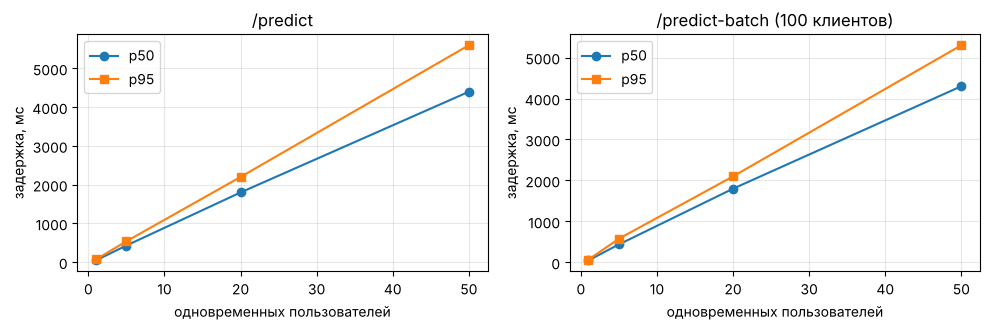

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, name in zip(axes, ['/predict', '/predict-batch']):
    t = load_tab[load_tab['эндпоинт'] == name]
    ax.plot(t['пользователей'], t['p50, мс'], 'o-', label='p50')
    ax.plot(t['пользователей'], t['p95, мс'], 's-', label='p95')
    ax.set_title(name + (' (100 клиентов)' if 'batch' in name else ''))
    ax.set_xlabel('одновременных пользователей'); ax.set_ylabel('задержка, мс'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('reports/load_latency.png', dpi=150); plt.show()

In [26]:
# одиночные запросы против пакета: 1000 клиентов
sess = requests.Session()
lat = []
t0 = time.perf_counter()
for c in clients[:1000]:
    t1 = time.perf_counter()
    sess.post(f'{URL}/predict', json=c).raise_for_status()
    lat.append(time.perf_counter() - t1)
single_total = time.perf_counter() - t0

def timed_batch(items, repeats=5):
    times = []
    for _ in range(repeats):
        t1 = time.perf_counter()
        r = sess.post(f'{URL}/predict-batch', json=items)
        r.raise_for_status()
        times.append(time.perf_counter() - t1)
    assert len(r.json()['proba']) == len(items)
    return np.array(times)

b1000 = timed_batch(clients[:1000])
# требование варианта: суточный пакет 10 000 клиентов за 60 с (клиенты тестовой выборки с повтором)
batch10k = [clients[i % len(clients)] for i in range(10_000)]
b10k = timed_batch(batch10k)
mode_tab = pd.DataFrame([
    {'режим': '1000 одиночных запросов подряд', 'время, с': single_total,
     'клиентов/с': 1000 / single_total, 'p50 запроса, мс': 1000 * np.median(lat), 'p95 запроса, мс': 1000 * np.quantile(lat, .95)},
    {'режим': '1 пакет × 1000 (медиана 5 повторов)', 'время, с': np.median(b1000),
     'клиентов/с': 1000 / np.median(b1000), 'p50 запроса, мс': 1000 * np.median(b1000), 'p95 запроса, мс': 1000 * b1000.max()},
    {'режим': '1 пакет × 10 000 (медиана 5 повторов)', 'время, с': np.median(b10k),
     'клиентов/с': 10_000 / np.median(b10k), 'p50 запроса, мс': 1000 * np.median(b10k), 'p95 запроса, мс': 1000 * b10k.max()},
]).round(3)
mode_tab.to_csv('reports/batch_vs_single.csv', index=False)
print(f'ускорение пакета над одиночными: ×{single_total / np.median(b1000):.0f}; '
      f'10 000 клиентов за {b10k.max():.2f} с в худшем из 5 повторов — требование 60 с выполнено с запасом ×{60 / b10k.max():.0f}')
mode_tab

ускорение пакета над одиночными: ×542; 10 000 клиентов за 0.80 с в худшем из 5 повторов — требование 60 с выполнено с запасом ×75


,режим,"время, с",клиентов/с,"p50 запроса, мс","p95 запроса, мс"
0,1000 одиночных запросов подряд,48.638,20.560,45.285,65.190
1,1 пакет × 1000 (медиана 5 повторов),0.090,11135.737,89.801,93.738
2,1 пакет × 10 000 (медиана 5 повторов),0.501,19956.673,501.086,800.532


In [27]:
# условия измерения
print('CPU:', os.cpu_count(), '| платформа:', 'Google Colab' if IN_COLAB else sys.platform,
      '| сервер uvicorn: 1 процесс, фоновый поток ядра | Locust — отдельный процесс на той же машине')

CPU: 4 | платформа: linux | сервер uvicorn: 1 процесс, фоновый поток ядра | Locust — отдельный процесс на той же машине


## Шаг 7. Дрейф данных

Эталон — тестовая выборка. Сценарий варианта 1 — **рост доли помесячных договоров**: например, оператор
запустил помесячный тариф без обязательств, и в суточный пакет попадает больше клиентов Month-to-month.
Сдвиг моделируется не шумом, а перевзвешенной выборкой реальных клиентов эталона: строки с помесячным
договором выбираются с большей вероятностью. Так меняется доля `Contract`, а вместе с ней — сопряжённые
признаки (у помесячных клиентов меньше стаж и `TotalCharges`, чаще оплата Electronic check и оптоволокно),
причём каждая строка остаётся реалистичной. Разметка известна, поэтому видно и изменение качества.

In [28]:
from evidently import Report, Dataset, DataDefinition
from evidently.presets import DataDriftPreset

NUM = ['tenure', 'MonthlyCharges', 'TotalCharges']
DEF = DataDefinition(numerical_columns=NUM, categorical_columns=[c for c in F.INPUT_COLUMNS if c not in NUM])
ref_X, ref_y = X_test.reset_index(drop=True), y_test.reset_index(drop=True)
ref_clean = F.clean(ref_X)[F.INPUT_COLUMNS]
P0 = (ref_X['Contract'] == 'Month-to-month').mean()
champion = bundle['pipeline']
THR = bundle['threshold']
ref_proba = champion.predict_proba(ref_X)[:, 1]


def month_to_month_shift(X, y, share, n=None, seed=0):
    """Выборка из эталона, в которой доля Month-to-month равна share."""
    rng = np.random.default_rng(seed)
    m2m = (X['Contract'] == 'Month-to-month').to_numpy()
    p0 = m2m.mean()
    w = np.where(m2m, share / p0, (1 - share) / (1 - p0))
    idx = rng.choice(len(X), size=n or len(X), replace=True, p=w / w.sum())
    return X.iloc[idx].reset_index(drop=True), y.iloc[idx].reset_index(drop=True)


def drift_check(cur_X, save_html=None):
    snap = Report([DataDriftPreset()]).run(
        reference_data=Dataset.from_pandas(ref_clean, data_definition=DEF),
        current_data=Dataset.from_pandas(F.clean(cur_X)[F.INPUT_COLUMNS], data_definition=DEF))
    if save_html:
        snap.save_html(save_html)
    res = snap.dict()['metrics']
    cols = []
    for m in res[1:]:
        col, method, thr = m['config']['column'], m['config']['method'], m['config']['threshold']
        drifted = m['value'] < thr if 'p_value' in method else m['value'] >= thr
        cols.append({'признак': col, 'метод': method, 'значение': m['value'], 'порог': thr, 'дрейф': drifted})
    return res[0]['value']['share'], pd.DataFrame(cols)


def quality(cur_X, cur_y):
    p = champion.predict_proba(cur_X)[:, 1]
    return {'доля M2M': (cur_X['Contract'] == 'Month-to-month').mean(), 'доля ушедших': cur_y.mean(),
            'ROC-AUC': roc_auc_score(cur_y, p), 'стоимость/клиент, ₽': T.total_cost(cur_y, p, THR) / len(cur_y),
            'доля со скидкой': (p >= THR).mean(), 'PSI прогнозов': MON.psi(ref_proba, p)}

print('доля помесячных договоров в эталоне:', round(P0, 3))

доля помесячных договоров в эталоне: 0.549


In [29]:
# основной сценарий: доля помесячных договоров 55 % -> 75 %; отчёт Evidently сохраняется в HTML
cur_X, cur_y = month_to_month_shift(ref_X, ref_y, 0.75, seed=RANDOM_STATE)
share, col_tab = drift_check(cur_X, save_html='reports/drift_report.html')
print('доля сдвинувшихся признаков:', round(share, 3), f'({int(col_tab["дрейф"].sum())} из {len(col_tab)})')
col_tab.sort_values('значение', ascending=False).round(4)

доля сдвинувшихся признаков: 0.158 (3 из 19)


,признак,метод,значение,порог,дрейф
0,tenure,Wasserstein distance (normed),0.2323,0.1,True
2,TotalCharges,Wasserstein distance (normed),0.1544,0.1,True
16,Contract,Jensen-Shannon distance,0.1388,0.1,True
18,PaymentMethod,Jensen-Shannon distance,0.0667,0.1,False
13,TechSupport,Jensen-Shannon distance,0.0644,0.1,False
12,DeviceProtection,Jensen-Shannon distance,0.0514,0.1,False
10,OnlineSecurity,Jensen-Shannon distance,0.0480,0.1,False
14,StreamingTV,Jensen-Shannon distance,0.0440,0.1,False
6,Dependents,Jensen-Shannon distance,0.0402,0.1,False
5,Partner,Jensen-Shannon distance,0.0383,0.1,False


In [30]:
# сценарии разной силы, по 10 случайных выборок каждый: частота срабатывания и качество модели
SCENARIOS = {'контроль (без сдвига)': P0, 'M2M 60 %': 0.60, 'M2M 65 %': 0.65, 'M2M 70 %': 0.70,
             'M2M 75 %': 0.75, 'M2M 85 %': 0.85}
sim = []
for name, s in SCENARIOS.items():
    for seed in range(10):
        cx, cy = month_to_month_shift(ref_X, ref_y, s, seed=1000 + seed)
        sh, ct = drift_check(cx)
        sim.append({'сценарий': name, 'seed': seed, 'доля дрейфа': sh,
                    'Contract дрейф': bool(ct.set_index('признак').loc['Contract', 'дрейф']), **quality(cx, cy)})
sim = pd.DataFrame(sim)
drift_tab = sim.groupby('сценарий', sort=False).agg(
    **{'доля M2M': ('доля M2M', 'mean'), 'доля дрейфа (ср.)': ('доля дрейфа', 'mean'),
       'доля дрейфа (мин.)': ('доля дрейфа', 'min'), 'доля дрейфа (макс.)': ('доля дрейфа', 'max'),
       'Contract дрейф, %': ('Contract дрейф', lambda s: 100 * s.mean()),
       'PSI прогнозов': ('PSI прогнозов', 'mean'), 'доля ушедших': ('доля ушедших', 'mean'),
       'доля со скидкой': ('доля со скидкой', 'mean'), 'ROC-AUC': ('ROC-AUC', 'mean'),
       'стоимость/клиент, ₽': ('стоимость/клиент, ₽', 'mean')}).round(3)
drift_tab.to_csv('reports/drift_scenarios.csv')
drift_tab

,доля M2M,доля дрейфа (ср.),доля дрейфа (мин.),доля дрейфа (макс.),"Contract дрейф, %",PSI прогнозов,доля ушедших,доля со скидкой,ROC-AUC,"стоимость/клиент, ₽"
сценарий,,,,,,,,,,
контроль (без сдвига),0.550,0.000,0.000,0.000,0.0,0.007,0.266,0.628,0.848,385.209
M2M 60 %,0.601,0.000,0.000,0.000,0.0,0.013,0.284,0.669,0.841,395.089
M2M 65 %,0.652,0.058,0.000,0.105,0.0,0.037,0.299,0.703,0.831,410.532
M2M 70 %,0.697,0.142,0.053,0.158,80.0,0.066,0.319,0.736,0.829,406.615
M2M 75 %,0.745,0.158,0.158,0.158,100.0,0.124,0.338,0.775,0.816,414.422
M2M 85 %,0.854,0.216,0.158,0.316,100.0,0.342,0.377,0.856,0.788,429.638


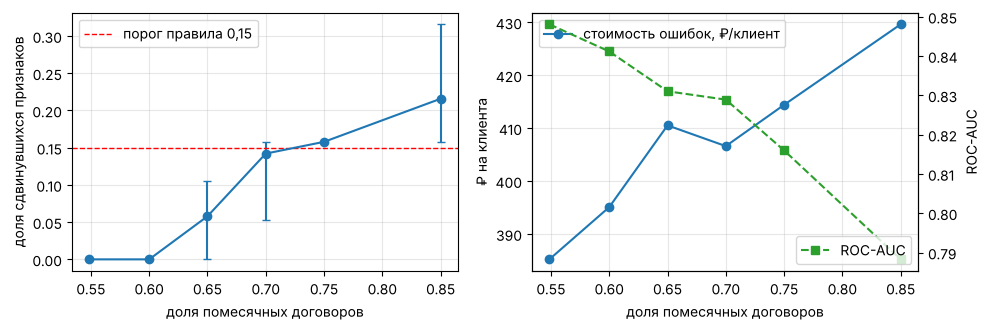

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
g = sim.groupby('сценарий', sort=False)
x = list(SCENARIOS.values())
axes[0].errorbar(x, g['доля дрейфа'].mean(), yerr=[g['доля дрейфа'].mean() - g['доля дрейфа'].min(),
                 g['доля дрейфа'].max() - g['доля дрейфа'].mean()], fmt='o-', capsize=3)
axes[0].axhline(0.15, color='r', ls='--', lw=1, label='порог правила 0,15')
axes[0].set_xlabel('доля помесячных договоров'); axes[0].set_ylabel('доля сдвинувшихся признаков'); axes[0].legend()
axes[1].plot(x, g['стоимость/клиент, ₽'].mean(), 'o-', label='стоимость ошибок, ₽/клиент')
ax2 = axes[1].twinx()
ax2.plot(x, g['ROC-AUC'].mean(), 's--', color='C2', label='ROC-AUC')
axes[1].set_xlabel('доля помесячных договоров'); axes[1].set_ylabel('₽ на клиента'); ax2.set_ylabel('ROC-AUC')
axes[1].legend(loc='upper left'); ax2.legend(loc='lower right')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('reports/drift_scenarios.png', dpi=150); plt.show()

**Правило переобучения** (проверяется автоматически, см. функцию `retrain_decision` ниже):

1. *Ежедневно*, после ночного пакетного скоринга, суточный пакет сравнивается с эталоном (тестовая выборка
   обучающего периода) отчётом Evidently `DataDriftPreset` с методами по умолчанию. Срабатывание дня —
   доля сдвинувшихся признаков **≥ 0,15** (не менее 3 из 19) **или** PSI распределения прогнозов **≥ 0,1**.
2. *Ежемесячно*, когда становится известен факт ухода клиентов, оценённых месяц назад (горизонт прогноза),
   на выборке не менее 1000 размеченных клиентов: ROC-AUC **< 0,819** (приёмочный уровень 0,849 − 0,03) **или**
   стоимость ошибок **> 1,2 ×** эталонной (> 459 ₽ на клиента).
3. *Действие*: если условие 1 выполнено **3 дня подряд** либо выполнено условие 2 — переобучение того же
   пайплайна (`src/train.py`, параметры ЛР1, порог заново по минимуму стоимости на OOF) на данных за
   последние 12 месяцев; новая версия регистрируется в реестре с псевдонимом `challenger` и получает
   `champion`, только если на отложенном последнем месяце её стоимость ошибок ниже, а ROC-AUC не ниже, чем
   у текущей; иначе — разбор признаков вручную. Эталон для проверки 1 после замены модели обновляется.

Пороги выбраны по моделированию выше, а не взяты из примера методички (30 %): при росте доли помесячных
договоров сдвиг сосредоточен в 3 сопряжённых признаках (`Contract`, `tenure`, `TotalCharges`), остальные
16 признаков почти не меняются, поэтому даже сильный сдвиг (85 %) даёт долю ~0,2–0,3. Порог 0,15 (3 из 19)
ни разу не срабатывает без сдвига и при 60 %, а при 75 % — всегда, т.е. там, где ROC-AUC уже опускается
ниже допуска 0,819. Требование «3 дня подряд» отсекает единичные выбросы суточного пакета.

In [32]:
RULE = {'drift_share': 0.15, 'psi': 0.1, 'days_in_row': 3, 'auc_min': 0.849 - 0.03,
        'cost_max': 1.2 * T.total_cost(ref_y, ref_proba, THR) / len(ref_y), 'min_labeled': 1000}


def day_alarm(drift_share, psi_pred):
    return drift_share >= RULE['drift_share'] or psi_pred >= RULE['psi']


def retrain_decision(daily_alarms, labeled=None):
    """daily_alarms — флаги срабатывания по дням (последний — сегодня); labeled — (n, roc_auc, cost) за месяц."""
    k = RULE['days_in_row']
    if len(daily_alarms) >= k and all(daily_alarms[-k:]):
        return True, f'дрейф данных {k} дня подряд'
    if labeled and labeled[0] >= RULE['min_labeled'] and (labeled[1] < RULE['auc_min'] or labeled[2] > RULE['cost_max']):
        return True, 'качество на размеченной выборке ниже допуска'
    return False, 'переобучение не требуется'


sim['срабатывание'] = [day_alarm(a, b) for a, b in zip(sim['доля дрейфа'], sim['PSI прогнозов'])]
alarm_tab = sim.groupby('сценарий', sort=False)['срабатывание'].mean().mul(100).rename('дней со срабатыванием, %')
print(alarm_tab.to_string())
print('порог стоимости, ₽/клиент:', round(RULE['cost_max'], 1))
# пример: три суточных пакета подряд со сдвигом 75 %
days = [day_alarm(*(lambda cx: (drift_check(cx)[0], MON.psi(ref_proba, champion.predict_proba(cx)[:, 1])))(
    month_to_month_shift(ref_X, ref_y, 0.75, seed=s)[0])) for s in range(3)]
print('3 дня со сдвигом 75 %:', days, '->', retrain_decision(days))
print('3 дня без сдвига:', retrain_decision([False, False, False]))

сценарий
контроль (без сдвига)      0.0
M2M 60 %                   0.0
M2M 65 %                   0.0
M2M 70 %                  80.0
M2M 75 %                 100.0
M2M 85 %                 100.0
порог стоимости, ₽/клиент: 458.9


3 дня со сдвигом 75 %: [True, True, True] -> (True, 'дрейф данных 3 дня подряд')
3 дня без сдвига: (False, 'переобучение не требуется')


## Шаг 8. Веб-интерфейс Gradio

Интерфейс обращается к сервису по HTTP (`/predict`), а не к модели напрямую. Поля ввода соответствуют
схеме входа; результат — вероятность, решение, порог и версия модели. В Colab `share=True` даёт публичную
ссылку `*.gradio.live` (живёт до 1 недели или до остановки среды).

In [33]:
import gradio as gr

CAT_FIELDS = {c: s['values'] for c, s in schema['features'].items() if s['type'] == 'category'}
FIELDS = F.INPUT_COLUMNS
DEFAULT = {**clients[1]}


def score(*values):
    payload = dict(zip(FIELDS, values))
    payload['SeniorCitizen'] = int(payload['SeniorCitizen'] == 'Yes')
    payload['tenure'] = int(payload['tenure'])
    payload['TotalCharges'] = None if payload['TotalCharges'] in (None, '') else float(payload['TotalCharges'])
    r = requests.post(f'{URL}/predict', json=payload)
    if r.status_code != 200:
        errs = '\n'.join(f"- `{'.'.join(map(str, e['loc'][1:])) or 'объект'}`: {e['msg']}" for e in r.json()['detail'])
        return f'### Ошибка ввода ({r.status_code})\n{errs}'
    out = r.json()
    verdict = 'предложить скидку на удержание' if out['decision'] else 'скидка не нужна'
    return (f"### Вероятность ухода: {out['proba']:.3f}\n**Решение:** {verdict}  \n"
            f"Порог: {out['threshold']} · модель {MODEL_NAME} v{out['model_version']}")


def make_input(c):
    if c == 'SeniorCitizen':
        return gr.Radio(['No', 'Yes'], label='SeniorCitizen (пенсионер)', value='Yes' if DEFAULT[c] else 'No')
    if c in CAT_FIELDS:
        return gr.Dropdown(CAT_FIELDS[c], label=c, value=DEFAULT[c])
    return gr.Number(label=c, value=DEFAULT[c])


with gr.Blocks(title='Отток клиентов Telco — ЛР2') as demo:
    gr.Markdown('## Оценка риска ухода клиента (ЛР2, вариант 1)\nИнтерфейс вызывает REST-сервис `/predict`.')
    with gr.Row():
        inputs = []
        for chunk in (FIELDS[:7], FIELDS[7:14], FIELDS[14:]):
            with gr.Column():
                inputs += [make_input(c) for c in chunk]
    btn = gr.Button('Оценить', variant='primary')
    result = gr.Markdown()
    btn.click(score, inputs, result)

demo.launch(share=IN_COLAB, prevent_thread_lock=True, quiet=True)
print('локальный адрес:', demo.local_url, '| публичная ссылка:', demo.share_url)

локальный адрес: http://127.0.0.1:7860/ | публичная ссылка: None


In [34]:
# проверка интерфейса без браузера: тот же обработчик, что у кнопки
print(score(*[('Yes' if DEFAULT[c] else 'No') if c == 'SeniorCitizen' else DEFAULT[c] for c in FIELDS]))
print(score(*[('Yes' if DEFAULT[c] else 'No') if c == 'SeniorCitizen' else (-3 if c == 'tenure' else DEFAULT[c]) for c in FIELDS]))
assert requests.get(demo.local_url).status_code == 200

### Вероятность ухода: 0.762
**Решение:** предложить скидку на удержание  
Порог: 0.1 · модель lab2_terekhin v2
### Ошибка ввода (422)
- `tenure`: Input should be greater than or equal to 0


## Дополнительное задание: журнал запросов и суточный отчёт о прогнозах

Сервис пишет каждый запрос в `logs/predictions.jsonl` (время, эндпоинт, код ответа, число объектов,
задержка, версия модели, вероятности) в фоновом потоке. Журнал нагрузочного теста ротируется, затем
моделируются сутки работы: суточный пакет (тестовая выборка), несколько обращений из интерфейса,
ошибочный запрос и дополнительный пакет из сценария дрейфа (75 % помесячных договоров). По журналу
строится суточный отчёт с PSI распределения прогнозов относительно эталона — это и есть сигнал «PSI
прогнозов» из правила переобучения.

In [35]:
logger = SVC.STATE['logger']
logger.flush()
os.replace('logs/predictions.jsonl', f'logs/predictions_loadtest_{SESSION}.jsonl')   # ротация журнала

requests.post(f'{URL}/predict-batch', json=clients).raise_for_status()                 # суточный пакет
for c in clients[:20]:
    requests.post(f'{URL}/predict', json=c)                                            # одиночные запросы
requests.post(f'{URL}/predict', json={**clients[0], 'tenure': 'много'})                # ошибка клиента
drift_X, _ = month_to_month_shift(ref_X, ref_y, 0.75, seed=7)
requests.post(f'{URL}/predict-batch', json=PR.frame_to_records(drift_X)).raise_for_status()
logger.flush()

TODAY = time.strftime('%Y-%m-%d')
daily = MON.daily_report('logs/predictions.jsonl', TODAY, ref_proba, THR, out_html='reports/daily_report.html')
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in daily['summary'].items()},
                 ensure_ascii=False, indent=1))
daily['batches'].round(4)

{
 "day": "2026-10-23",
 "requests": 23,
 "rejected_422": 1,
 "objects_scored": 2838,
 "mean_proba": 0.3041,
 "share_offer": 0.7139,
 "expected_churners": 863.0385,
 "ref_mean_proba": 0.266,
 "ref_share_offer": 0.6288,
 "psi_day": 0.0346,
 "psi_level": "стабильно"
}


,ts,request_id,n,latency_ms,mean_proba,share_offer,psi,оценка
0,2026-10-23 17:44:29,be99db28800a,1409,80.29,0.2660,0.6295,0.0000,стабильно
22,2026-10-23 17:44:30,28b5a2ba60ca,1409,89.64,0.3429,0.7999,0.1545,умеренный сдвиг


In [36]:
daily['by_endpoint'].round(2)

,endpoint,status,requests,objects,latency_p50_ms,latency_p95_ms
0,/predict,200,20,20.0,48.47,60.45
1,/predict,422,1,0.0,NaN,NaN
2,/predict-batch,200,2,2818.0,84.96,89.17


## Шаг 9. Воспроизводимость

In [37]:
# зафиксированное окружение и версия данных
with open('requirements.txt', 'w') as f:
    f.write(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)
print('requirements.txt:', sum(1 for _ in open('requirements.txt')), 'пакетов')
print('md5 data/telco.csv:', T.file_md5('data/telco.csv'))
print('прогон этого ноутбука:', SESSION, '| запусков MLflow в эксперименте:', len(runs),
      '| версий модели в реестре:', len(client.search_model_versions(f"name='{MODEL_NAME}'")))
same = runs.groupby('tags.mlflow.runName')['metrics.roc_auc_test'].nunique()
print('метрики одноимённых запусков разных прогонов совпадают:', bool((same == 1).all()))
for p in ['src/features.py', 'src/train.py', 'src/predict.py', 'src/service.py', 'src/monitoring.py',
          'tests/test_service.py', 'locustfile.py', 'models/input_schema.json', 'reports/drift_report.html',
          'reports/daily_report.html', 'reports/load_summary.csv', 'reports/pytest.txt', 'requirements.txt']:
    print(f'{p:30s}', os.path.getsize(p), 'байт')
print(f'время выполнения ноутбука: {(time.time() - T_START) / 60:.1f} мин')

requirements.txt: 244 пакетов
md5 data/telco.csv: 3b0bfab28a8101b4e4fdd08025a5c235
прогон этого ноутбука: 20261023-173707 | запусков MLflow в эксперименте: 8 | версий модели в реестре: 2
метрики одноимённых запусков разных прогонов совпадают: True
src/features.py                5201 байт
src/train.py                   6163 байт
src/predict.py                 2914 байт
src/service.py                 7298 байт
src/monitoring.py              7501 байт
tests/test_service.py          4968 байт
locustfile.py                  918 байт
models/input_schema.json       2677 байт
reports/drift_report.html      4157875 байт
reports/daily_report.html      27675 байт
reports/load_summary.csv       606 байт
reports/pytest.txt             310 байт
requirements.txt               4450 байт
время выполнения ноутбука: 7.5 мин
